# 02 — Degradations gallery

**Goal:** see what a face photo looks like after the kinds of damage it suffers in real life before it reaches a KYC app.

In real onboarding, people send selfies from cheap phones, in bad light, through messaging apps.
A deepfake detector trained only on clean photos may fail on these damaged ones.
The project calls each kind of damage a **degradation** and gives it a **severity** from 1 (a little) to 5 (a lot).

This notebook only **shows pictures**. Nothing is trained, nothing is saved.

**How to use:** this notebook is made for **Kaggle**. Do the settings below once, then run the cells from top to
bottom (Shift+Enter). No GPU needed. The dataset is optional: without it, the notebook uses a made-up test image.

### Before you start: Kaggle settings

Open the right-hand panel of the notebook editor (the **>|** icon at the top right if it is hidden):

- **Settings → Internet → On.** Step 1 downloads the project code from GitHub. Kaggle asks you to verify your phone once.
- **Add Input → Datasets →** search **"140k Real and Fake Faces"** (by xhlulu) → **+**. These are the images.
  Kaggle attaches them read-only under `/kaggle/input/`, so nothing is downloaded or unzipped.

After you change a setting, Kaggle restarts the session: run the cells again from the top.

## Step 1 — Get the project and pick one face

**What this does, in plain words:**

1. Loads the Python tools we need.
2. Downloads the project code (`src/`, `configs/`) from GitHub into `/kaggle/working/`, the only folder on Kaggle
   where we can write files. If Internet is off, it tells you so in plain words.
3. Finds the dataset you attached with **Add Input** somewhere under `/kaggle/input/`.
4. Loads the project's damage code (`src/deepfake_kyc/degradations.py`).
5. Picks one random training face. If the dataset is not attached, it makes a simple test image instead,
   so the notebook still runs.

Cloning into '/kaggle/working/UOT_SCS_3546_041_Deep-Learning'...


Project folder: /kaggle/working/UOT_SCS_3546_041_Deep-Learning
Images folder: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
Using this face: fake / 0CJH5AQM85.jpg


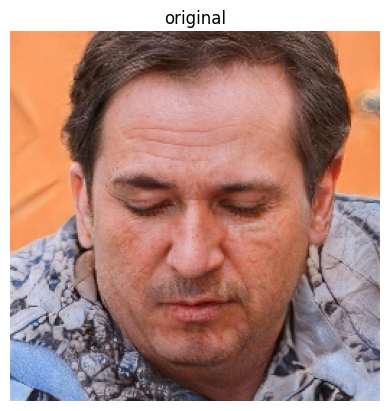

In [1]:
# 1. Tools we need
import os
import random
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# 2. Get the project code (src/ and configs/) from GitHub.
#    It goes into /kaggle/working: the only folder on Kaggle where we can write files.
REPO_URL = "https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning.git"
PROJECT_ROOT = Path("/kaggle/working/UOT_SCS_3546_041_Deep-Learning")

if not PROJECT_ROOT.exists():
    result = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)])
    if result.returncode != 0:
        raise RuntimeError("Could not download the project from GitHub. "
                           "Turn on Settings -> Internet in the right-hand panel, then run this cell again.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))   # lets Python import the project's own code
print("Project folder:", PROJECT_ROOT)

# 3. Find the dataset you attached with Add Input. Kaggle puts it somewhere under /kaggle/input.
def find_dataset():
    """Look inside /kaggle/input for the folder called real-vs-fake that has train/ valid/ test/."""
    for depth in range(1, 5):                                  # look 1, 2, 3, then 4 folders deep
        pattern = "/".join(["*"] * depth) + "/real-vs-fake"    # e.g. "*/*/real-vs-fake"
        for folder in Path("/kaggle/input").glob(pattern):
            if (folder / "train").is_dir():
                return folder
    return None

DATA_ROOT = find_dataset()       # folder with train/ valid/ test/, or None if not attached
if DATA_ROOT is None:
    print('Dataset not found: Add Input -> Datasets -> "140k Real and Fake Faces", then run this cell again.')
else:
    print("Images folder:", DATA_ROOT)

# 4. Load the project's damage code.
from deepfake_kyc.degradations import DEGRADATIONS

# 5. Pick one face: a real training photo if the dataset is attached, otherwise a simple test image.
def jpg_files(folder):
    """All .jpg files in one folder (reads the folder once, fast even with 50,000 files)."""
    names = sorted(os.listdir(folder)) if folder.is_dir() else []
    return [folder / name for name in names if name.lower().endswith(".jpg")]

train_images = []
if DATA_ROOT is not None:
    train_images = jpg_files(DATA_ROOT / "train" / "real") + jpg_files(DATA_ROOT / "train" / "fake")

if train_images:
    random.seed(0)                                  # same face every time you run the cell
    face_path = random.choice(train_images)
    face = Image.open(face_path).convert("RGB")
    print("Using this face:", face_path.parent.name, "/", face_path.name)
else:
    # Smooth colour gradient with a white circle: easy to see blur, blocks and noise on it.
    x = np.linspace(0, 255, 256, dtype=np.uint8)
    pixels = np.stack([np.tile(x, (256, 1)), np.tile(x[:, None], (1, 256)), np.full((256, 256), 128, np.uint8)], axis=2)
    yy, xx = np.mgrid[:256, :256]
    pixels[(yy - 128) ** 2 + (xx - 128) ** 2 < 60 ** 2] = 255
    face = Image.fromarray(pixels)
    print('No face photos found, so using a test image instead (attach "140k Real and Fake Faces" to see a real face).')

plt.imshow(face)
plt.axis("off")
plt.title("original")
plt.show()

## Step 2 — The five kinds of damage

| Name | What happens in real life |
|---|---|
| `jpeg` | The photo was squeezed to a small file, e.g. sent through WhatsApp |
| `blur` | Out-of-focus or shaky camera |
| `downscale` | A tiny low-resolution photo was stretched back up, so it looks blocky |
| `noise` | Photo taken in bad light, so it looks grainy |
| `screen` | Someone photographed a screen showing the face: stripes (moiré), colour tint, a little blur |

**Try one yourself:** change `name` and `severity` below and run the cell again.

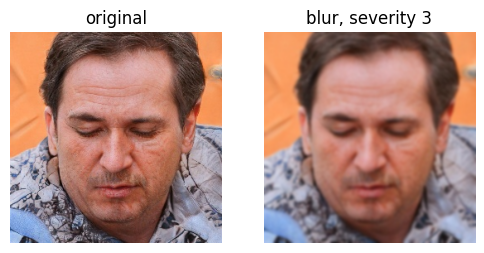

In [2]:
name = "blur"      # try "jpeg", "blur", "downscale", "noise" or "screen"
severity = 3       # 1 = a little damage ... 5 = a lot

damage = DEGRADATIONS[name](severity)   # build the damage step
damaged_face = damage(face)             # apply it to our face

fig, (left, right) = plt.subplots(1, 2, figsize=(6, 3))
left.imshow(face)
left.set_title("original")
right.imshow(damaged_face)
right.set_title(f"{name}, severity {severity}")
left.axis("off")
right.axis("off")
plt.show()

## Step 3 — The full gallery

**What this does:** one row per kind of damage, one column per severity (the first column is the original).

**Why:** later, notebook 03 shows charts like *"accuracy drops at blur severity 4"*. This grid shows you what
*blur severity 4* actually looks like, so you can judge whether that much damage is realistic.
It is also a good figure for the report.

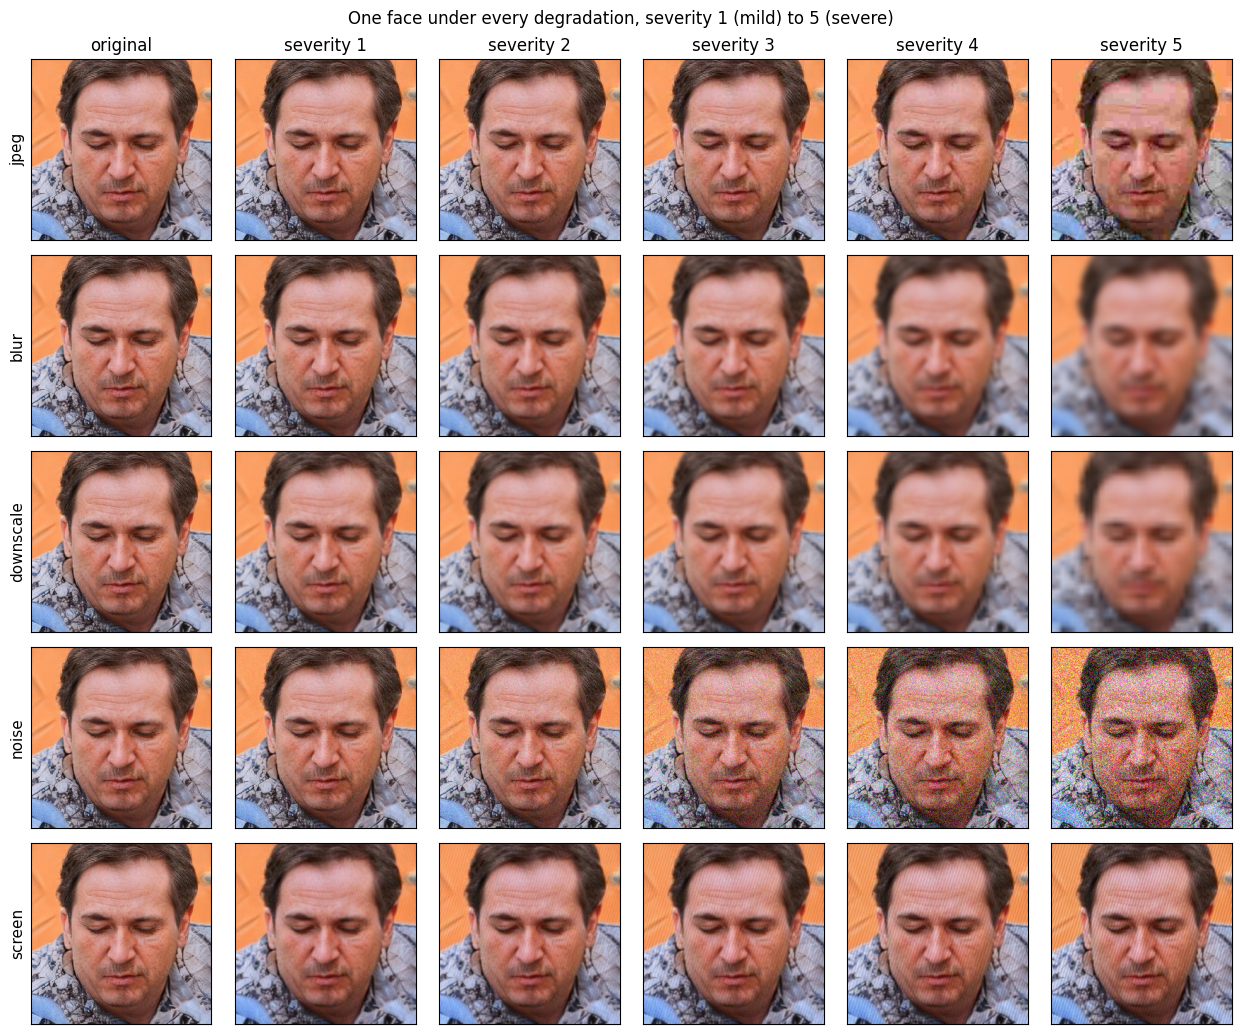

In [3]:
names = list(DEGRADATIONS)     # ['jpeg', 'blur', 'downscale', 'noise', 'screen']
severities = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(len(names), 6, figsize=(12.6, 2.1 * len(names)))
for row, name in enumerate(names):
    # first column: the original face
    axes[row, 0].imshow(face)
    axes[row, 0].set_ylabel(name, fontsize=11)
    # next five columns: severity 1 to 5
    for severity in severities:
        axes[row, severity].imshow(DEGRADATIONS[name](severity)(face))

for col, title in enumerate(["original"] + [f"severity {s}" for s in severities]):
    axes[0, col].set_title(title)
for ax in axes.flat:           # hide the axis numbers on every small picture
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("One face under every degradation, severity 1 (mild) to 5 (severe)")
plt.tight_layout()
plt.show()

## Where this same damage code is used later

The pictures above come from `src/deepfake_kyc/degradations.py`. The project uses that same code in two places:

- **Training (makes the model tougher):** `augment.degradation: true` in `configs/base.yaml` (on for every
  experiment except the `06_effnet_clean` control) randomly damages half of the training images,
  so the model gets used to them.
- **Testing (measures how tough the model is):** notebook 03 (Step 1b) or notebook 05 (Step 9) score a model at
  every kind and severity of damage and save the scores in `outputs/<experiment>/eval_test.csv`.

## Next

Notebook **05** trains the models; notebook **03** reads the `eval_test.csv` files and charts how accuracy
changes as the damage gets worse.